In [1]:
import networkx as nx
import random
import numpy as np
import pandas as pd
import time
from grakel import datasets, GraphKernel, graph_from_networkx
import toper
import matplotlib.pyplot as plt
import matplotlib

# import mag_graph
# from magnipy.magnitude.distances import get_dist
# from mag_graph.process import get_mag_graphs, get_weight_diffs, get_funs_diff, get_mag_areas, get_mag_funs_graphs, get_funs_df
# from mag_graph.baselines.spectral_zoo import est_moment

In [2]:
def gen_graphs_complexity(n_nodes,  n_resamples, nprop=2):
    np.random.seed(43)
    random.seed(314)
    graphs = {n: [] for n in n_nodes}
    for n in n_nodes:
        for i in range(n_resamples):
            graph = nx.erdos_renyi_graph(n=n, p=nprop/n)
            graphs[n].append(graph)
    return graphs

In [3]:
n_nodes = [20*i*2 for i in range(1,5)]
n_resamples = 5

graphs = gen_graphs_complexity(n_nodes=n_nodes, n_resamples=n_resamples)

In [105]:
metric = 'shortest_path_distance'
times = {}

# magnitude

times[f'spread_{metric}'] = {}
for n in n_nodes:
    samples = []
    for i in range(n_resamples):
        graph = graphs[n][i]

        compute_at_cardinality = None
        start_time = time.perf_counter()
        def dist_fn(G):
            return get_dist(G=G, X=None, X2=None, metric=metric, mode="structure")#"euclidean", mode="attributes") # structure # full

        all_spreads, weights_lists = get_mag_graphs([graph], dist_fn, ts=[1], upsample_to=n, n_repeats=3, scores_method='random', compute_at_cardinality=compute_at_cardinality)

        end_time = time.perf_counter()

        samples.append(end_time - start_time) 
    times[f'spread_{metric}'][(n, 'mean')] = np.mean(samples)
    times[f'spread_{metric}'][(n, 'std')] = np.std(samples)

# baselines
# kernels
kernel_names = [
            "shortest_path", 
            #"graphlet_sampling", 
            "pyramid_match", 
            #"svm_theta",
            "neighborhood_hash",
            "subtree_wl",
            "odd_sth",
            "propagation",
            "vertex_histogram",
            "weisfeiler_lehman",
            "core_framework",
            "weisfeiler_lehman_optimal_assignment"#,
            #"edge_histogram",
            #"multiscale_laplacian"
            ]
for k_ in kernel_names:
    times[f'kernel_{k_}'] = {}
    for n in n_nodes:
        samples = []
        for i in range(n_resamples):
            graph = graphs[n][i]
            graph2 = graphs[n][(i+1)%n_resamples]
            nx.set_node_attributes(graph, 1, name='feature') #dummy label for nx
            grakel_gen = graph_from_networkx([graph], as_Graph=True, node_labels_tag='feature')
            Gs = list(grakel_gen)
            start_time = time.perf_counter()
            # General kernels
            if k_ in ["weisfeiler_lehman" , "core_framework"]:
                gk = GraphKernel(kernel=[{"name": k_}, {"name": "shortest_path"}], normalize=True)
            # Base kernels
            else:
                gk = GraphKernel(kernel=[{"name": k_}], normalize=True)
            # Calculate the kernel matrix
            try:
                K = gk.fit_transform(Gs)
                end_time = time.perf_counter()
                samples.append(end_time - start_time)
            except Exception as e:
                print(f"Kernel {k_} failed with error: {e}")
        times[f'kernel_{k_}'][(n, 'mean')] = np.mean(samples)
        times[f'kernel_{k_}'][(n, 'std')] = np.std(samples)

#toper

for filt in ["degree", "popularity", "fricci", "oricci", "closeness"]:
    times[f'toper_{filt}'] = {}
    for n in n_nodes:
        samples = []
        for i in range(n_resamples):
            graph = graphs[n][i]
            try:
                start_time = time.perf_counter()
                F = toper.main([graph], [filt])#, num_segm=501) "closeness",
                end_time = time.perf_counter()
                if filt == "fricci":
                    filt = "forricci"
                elif filt == "oricci":
                    filt = "olricci"
                # array_super = np.array(F[f"{filt}_super"])
                # array_sub = np.array(F[f"{filt}_sub"])
                # array_sub_super = np.array(np.concatenate([F[f"{filt}_sub"], F[f"{filt}_super"]], axis=1))
                # print(f'shape of the toper arrays: {array_sub.shape}, {array_sub_super.shape}, {array_super.shape}')
                samples.append(end_time - start_time)
                suc = True
            except Exception as e:
                print(f"Toper failed with error: {e}")
                suc = False
        if suc:
            if filt == "forricci":
                    filt = "fricci"
            elif filt == "olricci":
                filt = "oricci"
            times[f'toper_{filt}'][(n, 'mean')] = np.mean(samples)
            times[f'toper_{filt}'][(n, 'std')] = np.std(samples)
    
    
    
# Spectral Zoo
times[f'spectral_zoo'] = {}
for n in n_nodes:
    samples = []
    for i in range(n_resamples):
        graph = graphs[n][i]
        start_time = time.perf_counter()
        moments = [est_moment(graph, 10000, 4)]
        #np.array(moments)
        end_time = time.perf_counter()
        array=np.array(moments)#[:, 1:]
        array = array[:, ~np.all(array == 0, axis=0)]
        samples.append(end_time - start_time)
    times[f'spectral_zoo'][(n, 'mean')] = np.mean(samples)
    times[f'spectral_zoo'][(n, 'std')] = np.std(samples)


Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1
Processing graph 0 / 1


/home/haeuserm/projects/mag_graph/.venv/lib/python3.12/site-packages/grakel/graph.py:314: UserWarning: changing format from "adjacency" to "all"
  warnings.warn('changing format from "adjacency" to "all"')
/home/haeuserm/projects/mag_graph/.venv/lib/python3.12/site-packages/grakel/graph.py:314: UserWarning: changing format from "adjacency" to "all"
  warnings.warn('changing format from "adjacency" to "all"')
/home/haeuserm/projects/mag_graph/.venv/lib/python3.12/site-packages/grakel/graph.py:314: UserWarning: changing format from "adjacency" to "all"
  warnings.warn('changing format from "adjacency" to "all"')
/home/haeuserm/projects/mag_graph/.venv/lib/python3.12/site-packages/grakel/graph.py:314: UserWarning: changing format from "adjacency" to "all"
  warnings.warn('changing format from "adjacency" to "all"')
/home/haeuserm/projects/mag_graph/.venv/lib/python3.12/site-packages/grakel/graph.py:314: UserWarning: changing format from "adjacency" to "all"
  warnings.warn('changing forma

done_thresh_degree
[Runtime] Degree: 0.007 sec
done_thresh_degree
[Runtime] Degree: 0.004 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.004 sec
done_thresh_degree
[Runtime] Degree: 0.004 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.005 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.005 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.008 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.007 sec
done_thresh_degree
[Runtime] Degree: 0.008 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.006 sec
done_thresh_degree
[Runtime] Degree: 0.011 sec
done_thresh_popularity
[Runtime] Popularity: 0.005 sec
done_

In [106]:
times

{'spread_shortest_path_distance': {(40, 'mean'): 0.1611800749997201,
  (40, 'std'): 0.025068977658264047,
  (80, 'mean'): 0.4824408719992789,
  (80, 'std'): 0.05041803392424744,
  (120, 'mean'): 1.226677061800001,
  (120, 'std'): 0.19011721139990456,
  (160, 'mean'): 2.319926767599827,
  (160, 'std'): 0.031140077445440135},
 'kernel_shortest_path': {(40, 'mean'): 0.0045012470000074245,
  (40, 'std'): 0.0010164612063264238,
  (80, 'mean'): 0.014306687000498641,
  (80, 'std'): 0.0020721752321636745,
  (120, 'mean'): 0.03176994800014654,
  (120, 'std'): 0.005069577945418246,
  (160, 'mean'): 0.051210269801231334,
  (160, 'std'): 0.009553233802077725},
 'kernel_pyramid_match': {(40, 'mean'): 0.0019458779999695253,
  (40, 'std'): 0.00046113049061189743,
  (80, 'mean'): 0.0038266140007181095,
  (80, 'std'): 0.0007354138103983385,
  (120, 'mean'): 0.005144325599394506,
  (120, 'std'): 9.078538355668105e-05,
  (160, 'mean'): 0.0373773645987967,
  (160, 'std'): 0.029394047446111172},
 'kernel_n

In [107]:
times_pd = pd.DataFrame.from_dict(times, orient='index')

In [108]:
times_pd

40                  80   \
                                                 mean       std      mean   
spread_shortest_path_distance                0.161180  0.025069  0.482441   
kernel_shortest_path                         0.004501  0.001016  0.014307   
kernel_pyramid_match                         0.001946  0.000461  0.003827   
kernel_neighborhood_hash                     0.000467  0.000230  0.000768   
kernel_subtree_wl                            0.000096  0.000054  0.000063   
kernel_odd_sth                               0.007275  0.002042  0.016934   
kernel_propagation                           0.001403  0.000619  0.001374   
kernel_vertex_histogram                      0.000097  0.000058  0.000107   
kernel_weisfeiler_lehman                     0.028293  0.020743  0.087839   
kernel_core_framework                        0.020201  0.013199  0.033177   
kernel_weisfeiler_lehman_optimal_assignment  0.000727  0.000155  0.001396   
toper_degree                                 0.284054  0.029685  0.276939   
toper_popularity                             0.279535  0.014920  0.289244   
toper_fricci                                 0.054373  0.108730  0.057172   
toper_oricci                                 0.171587  0.343157  0.133668   
toper_closeness                              0.287905  0.010419  0.288355   
spectral_zoo                                 0.035523  0.007737  0.035028   

                                                            120            \
                                                  std      mean       std   
spread_shortest_path_distance                0.050418  1.226677  0.190117   
kernel_shortest_path                         0.002072  0.031770  0.005070   
kernel_pyramid_match                         0.000735  0.005144  0.000091   
kernel_neighborhood_hash                     0.000497  0.000673  0.000043   
kernel_subtree_wl                            0.000012  0.000073  0.000011   
kernel_odd_sth                               0.001888  0.050334  0.011746   
kernel_propagation                           0.000248  0.056290  0.006964   
kernel_vertex_histogram                      0.000051  0.000108  0.000018   
kernel_weisfeiler_lehman                     0.010836  0.213321  0.027644   
kernel_core_framework                        0.004025  0.083719  0.010858   
kernel_weisfeiler_lehman_optimal_assignment  0.000159  0.002078  0.000183   
toper_degree                                 0.005045  0.288896  0.010926   
toper_popularity                             0.007408  0.282318  0.019131   
toper_fricci                                 0.114331  0.059719  0.119423   
toper_oricci                                 0.267321  0.125761  0.251510   
toper_closeness                              0.011664  0.293547  0.016429   
spectral_zoo                                 0.005766  0.025727  0.001013   

                                                  160            
                                                 mean       std  
spread_shortest_path_distance                2.319927  0.031140  
kernel_shortest_path                         0.051210  0.009553  
kernel_pyramid_match                         0.037377  0.029394  
kernel_neighborhood_hash                     0.000937  0.000230  
kernel_subtree_wl                            0.000073  0.000011  
kernel_odd_sth                               0.086656  0.010968  
kernel_propagation                           0.060153  0.009708  
kernel_vertex_histogram                      0.000100  0.000011  
kernel_weisfeiler_lehman                     0.452240  0.056173  
kernel_core_framework                        0.154497  0.026056  
kernel_weisfeiler_lehman_optimal_assignment  0.002998  0.000633  
toper_degree                                 0.286128  0.008602  
toper_popularity                             0.294201  0.016186  
toper_fricci                                 0.056994  0.113976  
toper_oricci                                 0.146120  0.292226  


### plotting

In [10]:
times_df = pd.read_csv('mag_graph/complexity/results/time_complexities.csv', index_col=0, header=[0,1])

In [11]:
times_df

40                  80  \
                                                 mean       std      mean   
spread_shortest_path_distance                0.931449  0.095640  3.581606   
kernel_shortest_path                         0.029067  0.002649  0.130382   
kernel_pyramid_match                         0.022461  0.013075  0.040287   
kernel_neighborhood_hash                     0.002767  0.000503  0.003508   
kernel_subtree_wl                            0.000142  0.000109  0.000129   
kernel_odd_sth                               0.047357  0.005950  0.220882   
kernel_propagation                           0.006537  0.002231  0.006936   
kernel_vertex_histogram                      0.000223  0.000134  0.000210   
kernel_weisfeiler_lehman                     0.203390  0.028432  0.831842   
kernel_core_framework                        0.086106  0.014346  0.356698   
kernel_weisfeiler_lehman_optimal_assignment  0.003959  0.000165  0.007255   
toper_degree                                 0.171694  0.008882  0.192281   
toper_popularity                             0.186466  0.015163  0.186854   
toper_fricci                                 0.019324  0.057962  0.020992   
toper_oricci                                 0.367513  1.102518  0.370146   
toper_closeness                              0.213810  0.018847  0.267970   
spectral_zoo                                 0.310259  0.013759  0.288933   

                                                            120            \
                                                  std      mean       std   
spread_shortest_path_distance                0.087744  8.094858  0.111819   
kernel_shortest_path                         0.011885  0.256477  0.030841   
kernel_pyramid_match                         0.004012  0.064601  0.009169   
kernel_neighborhood_hash                     0.000656  0.004725  0.000266   
kernel_subtree_wl                            0.000034  0.000244  0.000096   
kernel_odd_sth                               0.061051  0.553475  0.075967   
kernel_propagation                           0.001623  0.433210  0.109205   
kernel_vertex_histogram                      0.000039  0.000243  0.000033   
kernel_weisfeiler_lehman                     0.089338  1.742432  0.094406   
kernel_core_framework                        0.040483  0.794184  0.068566   
kernel_weisfeiler_lehman_optimal_assignment  0.000324  0.010236  0.000561   
toper_degree                                 0.011492  0.186058  0.013078   
toper_popularity                             0.020114  0.194776  0.008289   
toper_fricci                                 0.062957  0.020281  0.060822   
toper_oricci                                 1.110423  0.355998  1.067985   
toper_closeness                              0.013461  0.318229  0.029590   
spectral_zoo                                 0.029267  0.275234  0.029752   

                                                   160            
                                                  mean       std  
spread_shortest_path_distance                16.524553  2.787106  
kernel_shortest_path                          0.494170  0.044684  
kernel_pyramid_match                          0.170027  0.034285  
kernel_neighborhood_hash                      0.006362  0.000738  
kernel_subtree_wl                             0.000161  0.000025  
kernel_odd_sth                                1.109105  0.072820  
kernel_propagation                            0.364067  0.032377  
kernel_vertex_histogram                       0.000197  0.000049  
kernel_weisfeiler_lehman                      3.468764  0.172440  
kernel_core_framework                         1.477753  0.096539  
kernel_weisfeiler_lehman_optimal_assignment   0.014444  0.002703  
toper_degree                                  0.192310  0.019704  
toper_popularity                              0.204147  0.008626  
toper_fricci                                  0.024477  0.073416  
toper_oricci                                  0.368

In [18]:
df

,spread_shortest_path_distance,spectral_zoo,kernel_core_framework,toper_degree
40,0.931449,0.310259,0.086106,0.171694
80,3.581606,0.288933,0.356698,0.192281
120,8.094858,0.275234,0.794184,0.186058
160,16.524553,0.291803,1.477753,0.192310


In [23]:
for method in methods:
    # plt.fill_between(
    x=df.index,
    y1=np.add(times_df.loc[[method], (slice(None), ['mean'])].values[0], times_df.loc[[method], (slice(None), ['std'])].values[0]),
    y2=np.subtract(times_df.loc[[method], (slice(None), ['mean'])].values[0], times_df.loc[[method], (slice(None), ['std'])].values[0]),
    alpha=0.2

In [22]:
n_nodes

[40, 80, 120, 160]

In [28]:
list(df.index)

['40', '80', '120', '160']

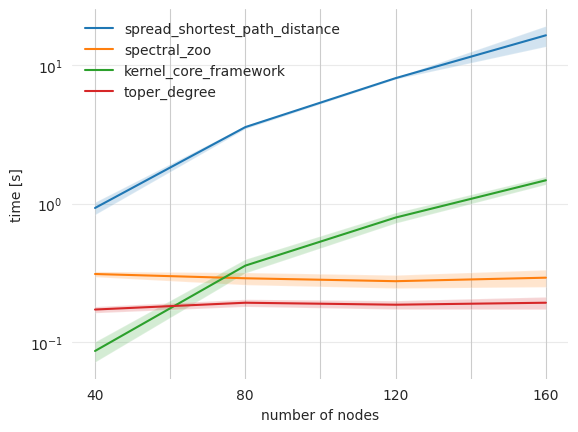

In [30]:
methods = ['spread_shortest_path_distance', 'spectral_zoo', 'kernel_core_framework',  'toper_degree'] # 'core_framework', 'shortest_path', 'weisfeiler_lehman',
n_nodes = [20*i*2 for i in range(1,5)]
n_graphs = 10
n_reruns = 10
df = times_df.loc[methods, (slice(None), ['mean'])].T
df = df.droplevel(level=1, axis=0)
df.plot(kind='line')


# x = list(comb_acc_nodes.loc[['funs_diff_coarsened_shortest_path_distance', 'spectral_zoo', 'propagation', 'closeness_super'], (slice(None), ['mean'])].T.index)

for method in methods:
    plt.fill_between(
        x=list(df.index),
        y1=np.add(times_df.loc[[method], (slice(None), ['mean'])].values[0], times_df.loc[[method], (slice(None), ['std'])].values[0]),
        y2=np.subtract(times_df.loc[[method], (slice(None), ['mean'])].values[0], times_df.loc[[method], (slice(None), ['std'])].values[0]),
        alpha=0.2)

# plt.ylim(0, 1)
plt.ylabel('time [s]')
# plt.xticks(ticks=n_nodes)
plt.xlabel('number of nodes')
# plt.xscale('log', base=2)
plt.yscale('log')
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.legend(frameon=False, fontsize = 'medium' )

ax.grid(visible=True, axis='y', alpha=0.4)
# ax.grid(axis='y', visible=True, which='major')

# plotting for ICLR
somehow old plotting script kinda lost?

In [44]:
times_df = pd.read_csv('complexity/results/time_complexities.csv', index_col=0, header=[0,1])
embedding_large_df = pd.read_csv('complexity/results/time_complexities_embedding_ngraphs_30_maxnodes_8192.csv', index_col=0, header=[0,1])
ph_large_df = pd.read_csv('complexity/results/time_complexities_ph_ngraphs_30_maxnodes_8192.csv', index_col=0, header = [0,1])
ph_vr_large_df = pd.read_csv('complexity/results/time_complexities_ph_vietorisrips_ngraphs_30_maxnodes_8192.csv', index_col=0, header=[0,1])
toper_large_df = pd.read_csv('complexity/results/time_complexities_toper_ngraphs_30_maxnodes_8192.csv', index_col=0, header= [0,1])
kernel_large_df = pd.read_csv('complexity/results/time_complexities_toper_ngraphs_30_maxnodes_8192.csv', index_col=0, header = [0,1])
divcurve_large_df = pd.read_csv('complexity/results/time_complexities_magnitude_ngraphs_30.csv', index_col=0, header=[0,1])
spectralzoo_large_df = pd.read_csv('complexity/results/time_complexities_spectralzoo_ngraphs_30.csv', index_col=0, header=[0,1])


In [ ]:
toper_large_df.loc['toper_all',:] = toper_large_df.sum(axis=0)

In [46]:
ph_vr_large_df.columns = pd.MultiIndex.from_tuples([(int(n), stat) for n, stat in ph_vr_large_df.columns])

In [50]:
long = ph_vr_large_df.stack(level=0, dropna=False).reset_index()

In [51]:
long

,level_0,level_1,mean,std
0,ph_vietoris_rips,128,20.525390,0.422963
1,ph_vietoris_rips,256,178.763682,2.997345
2,ph_vietoris_rips,512,1831.401079,10.965308
3,ph_vietoris_rips,1024,20653.827654,184.043747
4,ph_vietoris_rips,2048,20653.827654,NaN
5,ph_vietoris_rips,4096,20653.827654,NaN
6,ph_vietoris_rips,8192,20653.827654,NaN


In [49]:
long

mean         std
ph_vietoris_rips 128      20.525390    0.422963
                 256     178.763682    2.997345
                 512    1831.401079   10.965308
                 1024  20653.827654  184.043747
                 2048  20653.827654         NaN
                 4096  20653.827654         NaN
                 8192  20653.827654         NaN

In [47]:
ph_vr_large_df

128                   256                    512   \
                      mean       std        mean       std         mean   
ph_vietoris_rips  20.52539  0.422963  178.763682  2.997345  1831.401079   

                                     1024                      2048  \
                        std          mean         std          mean   
ph_vietoris_rips  10.965308  20653.827654  184.043747  20653.827654   

                          4096          8192  
                          mean          mean  
ph_vietoris_rips  20653.827654  20653.827654

In [40]:
# making one big table with all results we have
full_df = pd.concat([divcurve_large_df, embedding_large_df, kernel_large_df, ph_large_df, ph_vr_large_df, spectralzoo_large_df])

In [42]:
full_df.columns = pd.MultiIndex.from_tuples([(int(n), stat) for n, stat in full_df.columns])

In [43]:
full_df

1024                    128             \
                                       mean         std        mean       std   
spread_shortest_path_distance      6.448063    0.199171    0.754448  0.002953   
embedding_graph2vec                0.524806    0.171658    0.094522  0.091208   
embedding_feathergraph             0.595839    0.151898    0.077432  0.002714   
toper_degree                       0.402111    0.012081    0.313158  0.050417   
toper_popularity                   0.689539    0.002638    0.326355  0.001081   
toper_fricci                       0.714219    0.002973    0.336555  0.001095   
toper_oricci                     415.805459    0.475420  227.993346  1.210456   
toper_closeness                    3.958816    0.015320    0.569661  0.002929   
ph_degree                          0.237956    0.112609    0.041617  0.003172   
ph_forman_ricci_curvature          0.288650    0.122161    0.041971  0.000233   
ph_laplacian                       1.939751    0.126686    0.079770  0.000525   
ph_alpha_complex                   6.134313    0.022650    1.121442  0.013723   
ph_vietoris_rips               20653.827654  184.043747   20.525390  0.422963   
spectral_zoo                       1.006831    0.001677    0.930444  0.006773   

                                       2048                  256             \
                                       mean       std        mean       std   
spread_shortest_path_distance     22.522306  0.290693    0.759194  0.121597   
embedding_graph2vec                1.060315  0.144862    0.107539  0.001373   
embedding_feathergraph             1.264252  0.181957    0.179324  0.132321   
toper_degree                       0.531158  0.013676    0.308685  0.001171   
toper_popularity                   1.152887  0.003334    0.367330  0.000934   
toper_fricci                       1.150614  0.006607    0.387151  0.002053   
toper_oricci                     431.284193  1.213022  270.689726  1.244794   
toper_closeness                    7.830851  0.034844    1.141977  0.018343   
ph_degree                          0.473362  0.155264    0.061726  0.000939   
ph_forman_ricci_curvature          0.568095  0.148514    0.070120  0.000380   
ph_laplacian                       9.253718  0.156686    0.155002  0.000321   
ph_alpha_complex                  17.745799  0.096740    1.799347  0.013666   
ph_vietoris_rips               20653.827654       NaN  178.763682  2.997345   
spectral_zoo                       1.012792  0.002245    0.939062  0.001096   

                                       4096                   512              \
                                       mean       std         mean        std   
spread_shortest_path_distance     85.281809  0.230212     1.994127   0.010286   
embedding_graph2vec                2.272617  0.201342     0.269728   0.144275   
embedding_feathergraph             2.850275  0.191826     0.303713   0.117546   
toper_degree                       0.783605  0.006329     0.344374   0.005764   
toper_popularity                   2.172594  0.005638     0.463688   0.001362   
toper_fricci                       2.085204  0.004496     0.498001   0.004477   
toper_oricci                     512.776250  2.046381   363.989636   2.549465   
toper_closeness                   16.396939  0.080999     2.093941   0.010418   
ph_degree                          0.943296  0.193366     0.108322   0.001457   
ph_forman_ricci_curvature          1.217308  0.187592     0.130015   0.000389   
ph_laplacian                      71.799566  0.415523     0.445451   0.001204   
ph_alpha_complex                 100.375944  0.324148     2.907578   0.023305   
ph_vietoris_rips               20653.827654       NaN  1831.401079  10.965308   
spectral_zoo                       1.027567  0.005304     1.004388   0.006478   

                                       8192            
                                       mean       std  
spread_shortest_path_distance    323.530193  0.354655  
embedding_gr

In [6]:
embedding_large_df

128                 256                 512  \
                            mean       std      mean       std      mean   
embedding_graph2vec     0.094522  0.091208  0.107539  0.001373  0.269728   
embedding_feathergraph  0.077432  0.002714  0.179324  0.132321  0.303713   

                                      1024                2048            \
                             std      mean       std      mean       std   
embedding_graph2vec     0.144275  0.524806  0.171658  1.060315  0.144862   
embedding_feathergraph  0.117546  0.595839  0.151898  1.264252  0.181957   

                            4096                8192            
                            mean       std      mean       std  
embedding_graph2vec     2.272617  0.201342  4.594182  0.154021  
embedding_feathergraph  2.850275  0.191826  5.808805  0.471429

In [4]:
times_df

16                  32  \
                                                 mean       std      mean   
spread_shortest_path_distance                0.049638  0.001732  0.112911   
kernel_shortest_path                         0.004435  0.000368  0.012880   
kernel_pyramid_match                         0.006087  0.001440  0.009614   
kernel_neighborhood_hash                     0.000590  0.000082  0.000900   
kernel_subtree_wl                            0.000110  0.000088  0.000083   
kernel_odd_sth                               0.006492  0.000074  0.017856   
kernel_propagation                           0.043611  0.124436  0.002462   
kernel_vertex_histogram                      0.000090  0.000029  0.000082   
kernel_weisfeiler_lehman                     0.029387  0.000181  0.085970   
kernel_core_framework                        0.362899  1.045122  0.040559   
kernel_weisfeiler_lehman_optimal_assignment  0.001504  0.000220  0.002366   
toper_degree                                 0.108425  0.002926  0.111132   
toper_popularity                             0.107336  0.000470  0.108722   
toper_fricci                                 0.011022  0.033059  0.011212   
toper_oricci                                 2.945726  8.837172  3.137451   
toper_closeness                              0.109301  0.001986  0.112361   
spectral_zoo                                 0.192487  0.000307  0.181408   

                                                             64             \
                                                  std      mean        std   
spread_shortest_path_distance                0.002412  0.246662   0.001917   
kernel_shortest_path                         0.000037  0.047387   0.000068   
kernel_pyramid_match                         0.000061  0.020704   0.000089   
kernel_neighborhood_hash                     0.000009  0.001601   0.000033   
kernel_subtree_wl                            0.000005  0.000091   0.000006   
kernel_odd_sth                               0.000067  0.075579   0.032145   
kernel_propagation                           0.000169  0.002997   0.000031   
kernel_vertex_histogram                      0.000005  0.000090   0.000004   
kernel_weisfeiler_lehman                     0.000162  0.306827   0.000675   
kernel_core_framework                        0.000156  0.147247   0.000410   
kernel_weisfeiler_lehman_optimal_assignment  0.000040  0.004310   0.000079   
toper_degree                                 0.012062  0.108269   0.001026   
toper_popularity                             0.000945  0.111607   0.000770   
toper_fricci                                 0.033630  0.011918   0.035746   
toper_oricci                                 9.412347  3.602125  10.806367   
toper_closeness                              0.000566  0.127102   0.001414   
spectral_zoo                                 0.000625  0.186213   0.000880   

                                                  128                  256  \
                                                 mean        std      mean   
spread_shortest_path_distance                0.740987   0.002642  2.149804   
kernel_shortest_path                         0.220564   0.000493  0.873898   
kernel_pyramid_match                         0.040568   0.000144  0.060197   
kernel_neighborhood_hash                     0.003092   0.000227  0.005788   
kernel_subtree_wl                            0.000103   0.000004  0.000137   
kernel_odd_sth                               0.370523   0.044791  1.897025   
kernel_propagation                           0.004412   0.000099  0.007571   
kernel_vertex_histogram                      0.000105   0.000005  0.000135   
kernel_weisfeiler_lehman                     1.406575   0.005280  5.539747   
kernel_core_framework                        0.644358   0.001337  2.590572   
kernel_weisfeiler_lehman_optimal_assignment  0.008200   0.000119  0.015777   
toper_degree                                 0.109699   0.000714  0.113451   
toper_popula

In [ ]:
fast_divcurves_times_df = pd.read_csv('results_cluster/time_complexities_fast_divcurve_ngraphs_30_maxnodes_8192.csv', index_col=0, header=[0,1]) 

In [16]:
fast_divcurves_times_df *= 2800/2500

In [17]:
fast_divcurves_times_df

16                  32            \
                                   mean       std      mean       std   
spread_shortest_path_distance  0.040101  0.002832  0.064536  0.000641   

                                     64                 128            \
                                   mean       std      mean       std   
spread_shortest_path_distance  0.109059  0.000806  0.279663  0.135846   

                                    256                 512            \
                                   mean       std      mean       std   
spread_shortest_path_distance  0.180218  0.001754  0.564135  0.006648   

                                   1024                2048            \
                                   mean       std      mean       std   
spread_shortest_path_distance  1.942118  0.021951  7.143907  0.037999   

                                    4096                  8192            
                                    mean       std        mean       std  
spread_shortest_path_distance  28.579293  0.296781  115.094862  0.429187

In [11]:
full_df

1024                     128            \
                                       mean         std        mean       std   
spread_shortest_path_distance      6.448063    0.199171    0.754448  0.002953   
embedding_graph2vec                0.524806    0.171658    0.094522  0.091208   
embedding_feathergraph             0.595839    0.151898    0.077432  0.002714   
toper_degree                       0.402111    0.012081    0.313158  0.050417   
toper_popularity                   0.689539    0.002638    0.326355  0.001081   
toper_fricci                       0.714219    0.002973    0.336555  0.001095   
toper_oricci                     415.805459    0.475420  227.993346  1.210456   
toper_closeness                    3.958816    0.015320    0.569661  0.002929   
ph_degree                          0.237956    0.112609    0.041617  0.003172   
ph_forman_ricci_curvature          0.288650    0.122161    0.041971  0.000233   
ph_laplacian                       1.939751    0.126686    0.079770  0.000525   
ph_alpha_complex                   6.134313    0.022650    1.121442  0.013723   
ph_vietoris_rips               20653.827654  184.043747   20.525390  0.422963   
spectral_zoo                       1.006831    0.001677    0.930444  0.006773   

                                       2048                   256            \
                                       mean       std        mean       std   
spread_shortest_path_distance     22.522306  0.290693    0.759194  0.121597   
embedding_graph2vec                1.060315  0.144862    0.107539  0.001373   
embedding_feathergraph             1.264252  0.181957    0.179324  0.132321   
toper_degree                       0.531158  0.013676    0.308685  0.001171   
toper_popularity                   1.152887  0.003334    0.367330  0.000934   
toper_fricci                       1.150614  0.006607    0.387151  0.002053   
toper_oricci                     431.284193  1.213022  270.689726  1.244794   
toper_closeness                    7.830851  0.034844    1.141977  0.018343   
ph_degree                          0.473362  0.155264    0.061726  0.000939   
ph_forman_ricci_curvature          0.568095  0.148514    0.070120  0.000380   
ph_laplacian                       9.253718  0.156686    0.155002  0.000321   
ph_alpha_complex                  17.745799  0.096740    1.799347  0.013666   
ph_vietoris_rips               20653.827654       NaN  178.763682  2.997345   
spectral_zoo                       1.012792  0.002245    0.939062  0.001096   

                                       4096                    512             \
                                       mean       std         mean        std   
spread_shortest_path_distance     85.281809  0.230212     1.994127   0.010286   
embedding_graph2vec                2.272617  0.201342     0.269728   0.144275   
embedding_feathergraph             2.850275  0.191826     0.303713   0.117546   
toper_degree                       0.783605  0.006329     0.344374   0.005764   
toper_popularity                   2.172594  0.005638     0.463688   0.001362   
toper_fricci                       2.085204  0.004496     0.498001   0.004477   
toper_oricci                     512.776250  2.046381   363.989636   2.549465   
toper_closeness                   16.396939  0.080999     2.093941   0.010418   
ph_degree                          0.943296  0.193366     0.108322   0.001457   
ph_forman_ricci_curvature          1.217308  0.187592     0.130015   0.000389   
ph_laplacian                      71.799566  0.415523     0.445451   0.001204   
ph_alpha_complex                 100.375944  0.324148     2.907578   0.023305   
ph_vietoris_rips               20653.827654       NaN  1831.401079  10.965308   
spectral_zoo                       1.027567  0.005304     1.004388   0.006478   

                                       8192            
                                       mean       std  
spread_shortest_path_distance    323.530193  0.354655  
embedding_gr

### reconstructed ICLR plot
combines the small (8-64 nodes) and large (128-8192 nodes) runs; TopER is the sum over all filtrations

In [2]:
# combine all timing results into one long dataframe (method, n_nodes, mean, std)
def load_times(name, mod_info=None, add_sum_as=None):
    df = pd.read_csv(f'complexity/results/time_complexities_{name}.csv', index_col=0, header=[0, 1])
    df.columns = pd.MultiIndex.from_tuples([(int(n), stat) for n, stat in df.columns])
    if mod_info is not None:
        mod, detail = mod_info
        if mod == 'add_sum_as':
            df.loc[detail, :] = df.sum(axis=0, min_count=len(df))
        elif mod == 'factor':
            df.loc[:, (slice(None), 'mean')] *= detail
    long = df.stack(level=0, dropna=False).reset_index()
    long.columns = ['method', 'n_nodes'] + list(long.columns[2:])
    return long

files = [
    ('kernel_ngraphs_30_maxnodes_64',), ('kernel_ngraphs_30',),
    ('magnitude_ngraphs_30_maxnodes_64',), ('magnitude_ngraphs_30',),
    ('toper_ngraphs_30_maxnodes_64', ('add_sum_as', 'toper_all')), ('toper_ngraphs_30_maxnodes_8192', ('add_sum_as', 'toper_all')),
    ('embedding_ngraphs_30_maxnodes_64',), ('embedding_ngraphs_30_maxnodes_8192',),
    ('ph_ngraphs_30_maxnodes_64',), ('ph_ngraphs_30_maxnodes_8192',),
    ('ph_vietorisrips_ngraphs_30_maxnodes_8192',),
    ('spectralzoo_ngraphs_30',), ('fast_divcurve_ngraphs_30_maxnodes_8192', ('factor', 28/25)),
    ('fast_divcurve_ngraphs_30_maxnodes_8192_node201',)
]
full_df = pd.concat([load_times(*f) for f in files], ignore_index=True)
full_df = full_df.drop_duplicates(subset=['method', 'n_nodes'], keep='first')
full_df = full_df[full_df['n_nodes'] >= 16].sort_values(['method', 'n_nodes']).reset_index(drop=True)
full_df

,method,n_nodes,mean,std
0,embedding_feathergraph,16,0.024664,0.000298
1,embedding_feathergraph,32,0.032334,0.000352
2,embedding_feathergraph,64,0.047778,0.000612
3,embedding_feathergraph,128,0.077432,0.002714
4,embedding_feathergraph,256,0.179324,0.132321
...,...,...,...,...
244,toper_popularity,512,0.463688,0.001362
245,toper_popularity,1024,0.689539,0.002638
246,toper_popularity,2048,1.152887,0.003334
247,toper_popularity,4096,2.172594,0.005638


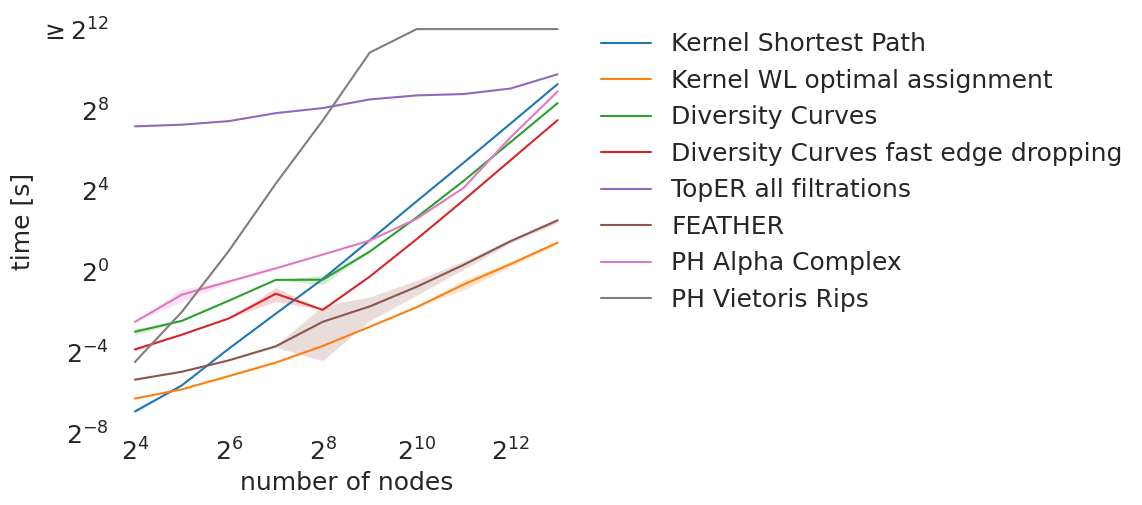

In [3]:
methods = {
    'kernel_shortest_path': 'Kernel Shortest Path',
    'kernel_weisfeiler_lehman_optimal_assignment': 'Kernel WL optimal assignment',
    'spread_shortest_path_distance': 'Diversity Curves',
    # 'spread_shortest_path_distance_fast': 'Diversity Curves fast edge dropping',
    'spread_shortest_path_distance_fast201': 'Diversity Curves fast edge dropping', 
    'toper_all': 'TopER all filtrations',
    'embedding_feathergraph': 'FEATHER',
    'ph_alpha_complex': 'PH Alpha Complex',
    'ph_vietoris_rips': 'PH Vietoris Rips',
}
y_cap = 2**12
matplotlib.rcParams.update({"font.size": 18})
fig, ax = plt.subplots(figsize=(6, 5.5))
for method, label in methods.items():
    d = full_df[full_df['method'] == method].sort_values('n_nodes')
    mean = d['mean'].to_numpy()
    std = d['std'].fillna(0).to_numpy()
    ax.plot(d['n_nodes'], np.clip(mean, None, y_cap), label=label)
    ax.fill_between(d['n_nodes'], np.clip(mean - std, 1e-12, y_cap), np.clip(mean + std, None, y_cap), alpha=0.2)

ax.set_xscale('log', base=2)
ax.set_yscale('log', base=2)
ax.set_xticks([2**i for i in range(4, 13, 2)])
yticks = [2**i for i in range(-8, 9, 4)] + [y_cap]
ax.set_yticks(yticks)
ax.set_yticklabels([f'$2^{{{int(np.log2(t))}}}$' for t in yticks[:-1]] + [r'$\geq 2^{12}$'])
ax.minorticks_off()
ax.set_xlabel('number of nodes')
ax.set_ylabel('time [s]')
for side in ['top', 'right', 'bottom', 'left']:
    ax.spines[side].set_visible(False)
ax.grid(visible=False)
ax.tick_params(length=0)
ax.legend(frameon=False, fontsize='medium', bbox_to_anchor=(1, 1), loc='upper left')
plt.savefig('complexity/results/time_complexity.pdf', bbox_inches='tight')
plt.savefig('complexity/results/time_complexity.png', bbox_inches='tight', dpi=200)
plt.show()